In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import nltk
import torch
import tensorflow as tf

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize


from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments
)

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, LSTM,GRU, Dense, Dropout, Bidirectional, Input
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


I0000 00:00:1794252228.683724      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


# Load & Explore The Data.

In [2]:
df = pd.read_csv("/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv")
df.head()

,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


In [3]:
print(df.shape)
print(df.columns.tolist())

(162421, 3)
['Unnamed: 0', 'product', 'narrative']


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df = df.drop(columns="Unnamed: 0", errors="ignore")

In [6]:
df.head()

,product,narrative
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report speciali...
4,credit_reporting,payment history missing credit report made mis...


In [7]:
df = df[['narrative', 'product']].dropna().copy()
df.columns = ['text', 'label']

df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'] != ''].copy()

before = len(df)
df = df.drop_duplicates(subset=['text', 'label']).reset_index(drop=True)

print(f"Rows removed as exact duplicates: {before - len(df)}")
print(f"Total samples after cleaning null/empty rows: {len(df)}")
print(f"Unique categories: {df['label'].nunique()}")
print("\nCategory distribution:")
print(df['label'].value_counts())


Rows removed as exact duplicates: 37735
Total samples after cleaning null/empty rows: 124676
Unique categories: 5

Category distribution:
label
credit_reporting       56303
debt_collection        21117
mortgages_and_loans    18759
credit_card            15024
retail_banking         13473
Name: count, dtype: int64


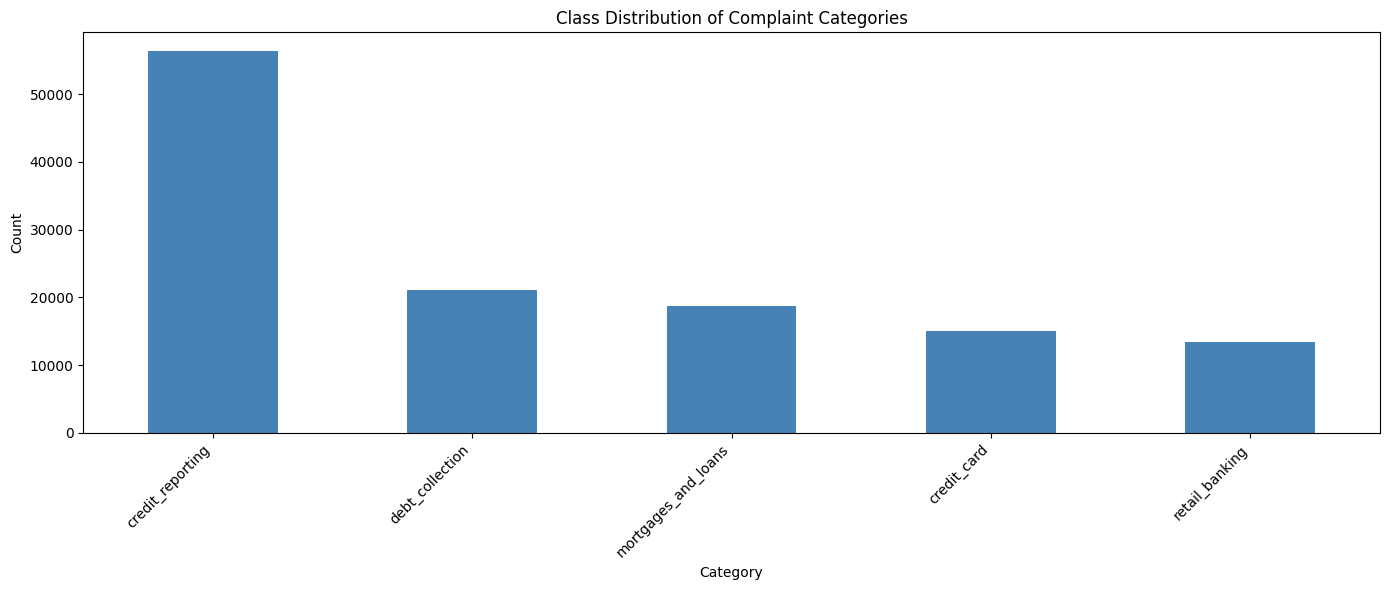

In [8]:
plt.figure(figsize=(14, 6))
df['label'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Class Distribution of Complaint Categories')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Text length statistics:
count    124676.000000
mean         87.117055
std         110.875369
min           1.000000
25%          30.000000
50%          58.000000
75%         104.000000
max        2685.000000
Name: text_length, dtype: float64


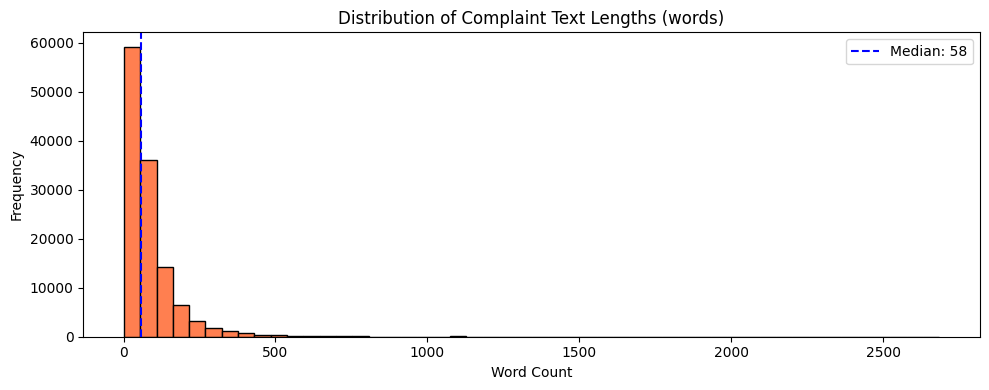

In [9]:
df['text_length'] = df['text'].apply(lambda x: len(x.split()))

print("Text length statistics:")
print(df['text_length'].describe())

plt.figure(figsize=(10, 4))
plt.hist(df['text_length'], bins=50, color='coral', edgecolor='black')
plt.title('Distribution of Complaint Text Lengths (words)')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.axvline(df['text_length'].median(), color='blue', linestyle='--',
            label=f"Median: {df['text_length'].median():.0f}")
plt.legend()
plt.tight_layout()
plt.show()

# Text Preprocessing

In [10]:
stop = set(stopwords.words('english'))
stop -= {'no', 'nor', 'not'}
wn = WordNetLemmatizer()

def remove_punc(text):
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'\bx+\b', ' ', text)
    text = ''.join(c for c in text if c not in string.punctuation)
    return text

def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop]

def lemmatize_tokens(tokens):
    return [wn.lemmatize(word) for word in tokens]


In [11]:
def preprocess(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = remove_punc(text)
    tokens = word_tokenize(text)
    tokens = remove_stopwords(tokens)
    tokens = lemmatize_tokens(tokens)
    tokens = [word for word in tokens if len(word) > 2 or word in {'no', 'nor', 'not'}]
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess)

df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)
print(f"Samples remaining after preprocessing: {len(df)}")


Samples remaining after preprocessing: 124676


In [12]:
print("\nOriginal:")
print(df['text'].iloc[0][:200])
print("\nCleaned:")
print(df['clean_text'].iloc[0][:200])


Original:
purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order 

Cleaned:
purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded sorry inform due unusually high order volume order shi


In [13]:
print("Shape      :", df.shape)
print("Columns    :", df.columns.tolist())
print("Labels     :", df['label'].unique())
print("Null texts :", df['clean_text'].isnull().sum())
print("\nSample:")
print(df[['clean_text', 'label']].head(3))

Shape      : (124676, 4)
Columns    : ['text', 'label', 'text_length', 'clean_text']
Labels     : ['credit_card' 'retail_banking' 'credit_reporting' 'mortgages_and_loans'
 'debt_collection']
Null texts : 0

Sample:
                                          clean_text           label
0  purchase order day shipping amount receive pro...     credit_card
1  forwarded message date tue subject please inve...     credit_card
2  forwarded message sent friday pdt subject fina...  retail_banking


Class distribution:
label
credit_reporting       56303
debt_collection        21117
mortgages_and_loans    18759
credit_card            15024
retail_banking         13473
Name: count, dtype: int64

Imbalance ratio: 4.18x


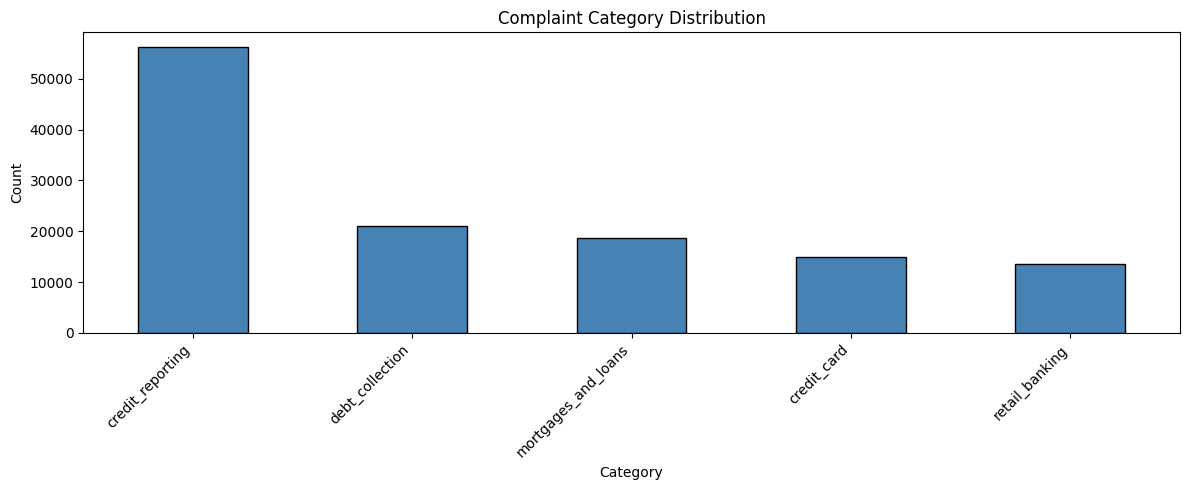

In [14]:
print("Class distribution:")
print(df['label'].value_counts())
print(f"\nImbalance ratio: {df['label'].value_counts().max() / df['label'].value_counts().min():.2f}x")


plt.figure(figsize=(12, 5))
df['label'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Complaint Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [15]:
print("Class distribution (original cleaned dataset):")
print(df['label'].value_counts())
print(f"Total samples: {len(df)}")


Class distribution (original cleaned dataset):
label
credit_reporting       56303
debt_collection        21117
mortgages_and_loans    18759
credit_card            15024
retail_banking         13473
Name: count, dtype: int64
Total samples: 124676


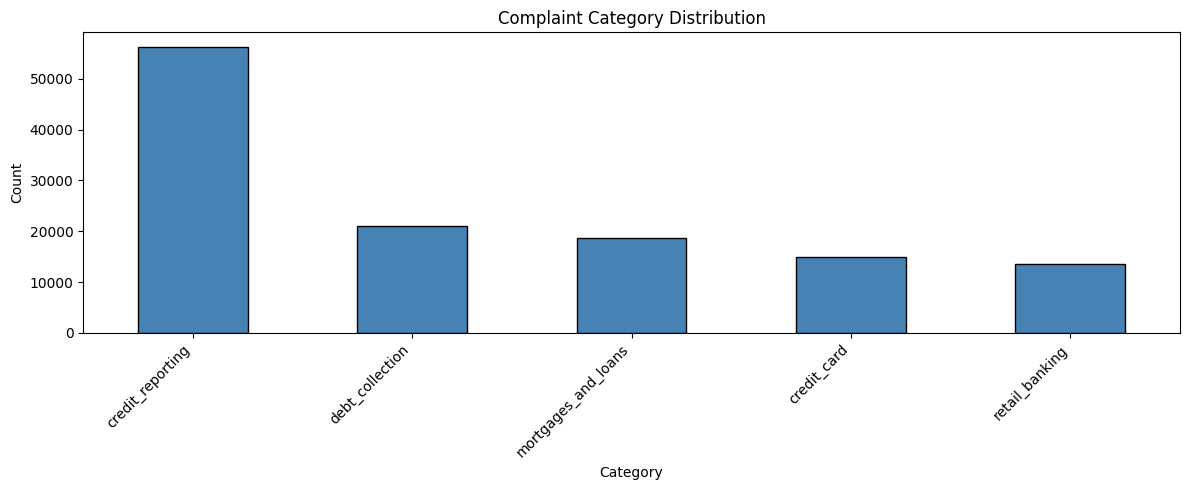

In [16]:
plt.figure(figsize=(12, 5))
df['label'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Complaint Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [17]:
le = LabelEncoder()
y = le.fit_transform(df['label'].astype(str))
X_text = df['clean_text'].astype(str).reset_index(drop=True)

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print(f"Training samples:   {len(X_train_text):,}")
print(f"Validation samples: {len(X_val_text):,}")
print(f"Test samples:       {len(X_test_text):,}")
print(f"Number of classes:  {len(le.classes_)}")


Training samples:   87,273
Validation samples: 18,701
Test samples:       18,702
Number of classes:  5


,Train,Validation,Test
credit_card,0.120507,0.120528,0.120468
credit_reporting,0.451594,0.451580,0.451609
debt_collection,0.169377,0.169349,0.169394
mortgages_and_loans,0.150459,0.150473,0.150465
retail_banking,0.108063,0.108069,0.108063


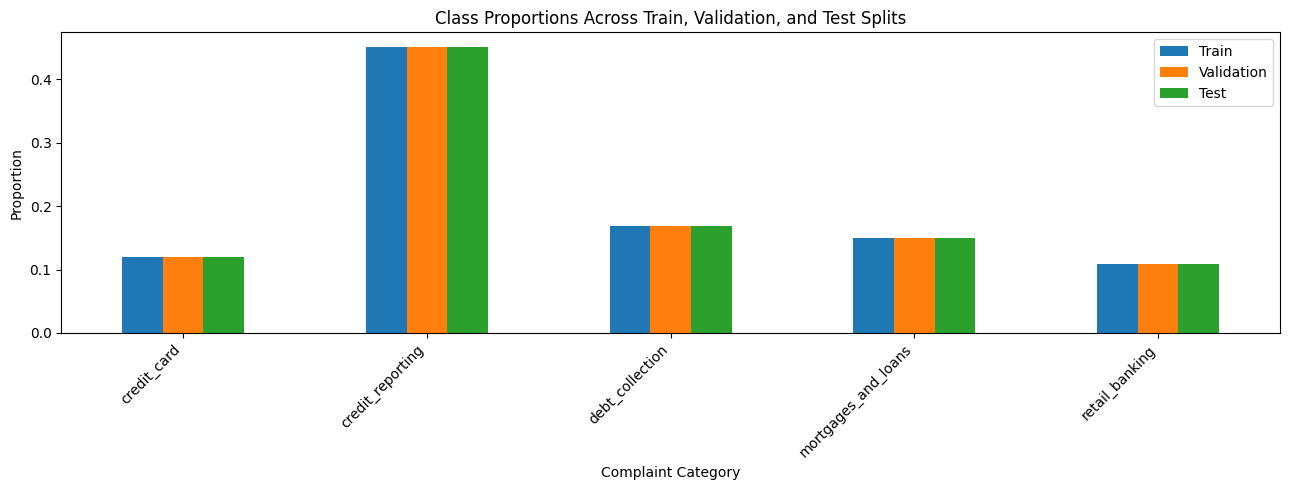

In [18]:
train_distribution = pd.Series(y_train).value_counts(normalize=True).sort_index()
val_distribution = pd.Series(y_val).value_counts(normalize=True).sort_index()
test_distribution = pd.Series(y_test).value_counts(normalize=True).sort_index()

split_distribution = pd.DataFrame({
    'Train': train_distribution,
    'Validation': val_distribution,
    'Test': test_distribution
}).fillna(0)

split_distribution.index = le.inverse_transform(split_distribution.index.astype(int))
display(split_distribution)

ax = split_distribution.plot(kind='bar', figsize=(13, 5))
ax.set_title('Class Proportions Across Train, Validation, and Test Splits')
ax.set_xlabel('Complaint Category')
ax.set_ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [19]:
VOCAB_SIZE = 30000
MAX_LEN = 200
EMBEDDING_DIM = 128
BATCH_SIZE = 64
EPOCHS = 25
NUM_CLASSES = len(le.classes_)

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)

word_index = tokenizer.word_index
actual_vocab = len(word_index)
retained_vocab = min(VOCAB_SIZE - 1, actual_vocab) 

print(f"Unique words found in training text: {actual_vocab:,}")
print(f"Vocabulary cap: {VOCAB_SIZE:,}")
if actual_vocab:
    print(f"Approximate vocabulary-entry coverage: {retained_vocab / actual_vocab:.1%}")


Unique words found in training text: 38,611
Vocabulary cap: 30,000
Approximate vocabulary-entry coverage: 77.7%


In [20]:
def encode_and_pad(texts):
    sequences = tokenizer.texts_to_sequences(texts)
    return pad_sequences(
        sequences,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )

X_train_pad = encode_and_pad(X_train_text)
X_val_pad = encode_and_pad(X_val_text)
X_test_pad = encode_and_pad(X_test_text)

print(f"X_train_pad shape: {X_train_pad.shape}")
print(f"X_val_pad shape:   {X_val_pad.shape}")
print(f"X_test_pad shape:  {X_test_pad.shape}")


X_train_pad shape: (87273, 200)
X_val_pad shape:   (18701, 200)
X_test_pad shape:  (18702, 200)


MAX_LEN = 100 covers 74.5% of sampled training sequences
MAX_LEN = 150 covers 86.7% of sampled training sequences
MAX_LEN = 200 covers 92.1% of sampled training sequences


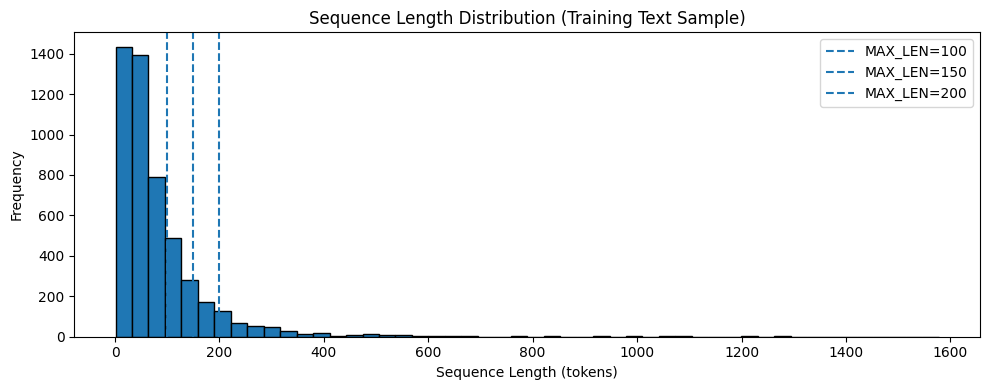

In [21]:
sample_texts = X_train_text.iloc[:min(5000, len(X_train_text))]
seq_lengths = [len(tokenizer.texts_to_sequences([text])[0]) for text in sample_texts]

for max_len in [100, 150, 200]:
    coverage = np.mean([length <= max_len for length in seq_lengths])
    print(f"MAX_LEN = {max_len} covers {coverage:.1%} of sampled training sequences")

plt.figure(figsize=(10, 4))
plt.hist(seq_lengths, bins=50, edgecolor='black')
for length in [100, 150, 200]:
    plt.axvline(length, linestyle='--', label=f'MAX_LEN={length}')
plt.title('Sequence Length Distribution (Training Text Sample)')
plt.xlabel('Sequence Length (tokens)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
classes_in_train = np.unique(y_train)
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=classes_in_train,
    y=y_train
)

class_weight_dict = {
    int(cls): float(weight)
    for cls, weight in zip(classes_in_train, class_weights_array)
}

print("Class weights:")
for class_id, weight in class_weight_dict.items():
    print(f"  {class_id} ({le.classes_[class_id]:<30}) -> {weight:.4f}")


Class weights:
  0 (credit_card                   ) -> 1.6597
  1 (credit_reporting              ) -> 0.4429
  2 (debt_collection               ) -> 1.1808
  3 (mortgages_and_loans           ) -> 1.3293
  4 (retail_banking                ) -> 1.8508


In [23]:
def make_callbacks():
    return [
        EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            verbose=1
        )
    ]


In [24]:
def build_simple_rnn():
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        ),
        SimpleRNN(128, return_sequences=True),
        Dropout(0.3),
        SimpleRNN(64),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

rnn_model = build_simple_rnn()
rnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 200, 128)       │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 200, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,889,733 (14.84 MB)

 Trainable params: 3,889,733 (14.84 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
print("Training SimpleRNN...")
history_rnn = rnn_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=make_callbacks(),
    verbose=1
)


Training SimpleRNN...
Epoch 1/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 59s 39ms/step - accuracy: 0.2258 - loss: 1.5943 - val_accuracy: 0.3586 - val_loss: 1.2130 - learning_rate: 0.0010
Epoch 2/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 47s 34ms/step - accuracy: 0.3863 - loss: 1.3165 - val_accuracy: 0.5034 - val_loss: 1.1640 - learning_rate: 0.0010
Epoch 3/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 47s 34ms/step - accuracy: 0.4157 - loss: 1.2650 - val_accuracy: 0.4719 - val_loss: 1.2729 - learning_rate: 0.0010
Epoch 4/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 47s 34ms/step - accuracy: 0.4473 - loss: 1.2228 - val_accuracy: 0.5203 - val_loss: 1.1215 - learning_rate: 0.0010
Epoch 5/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 47s 34ms/step - accuracy: 0.4492 - loss: 1.2188 - val_accuracy: 0.3574 - val_loss: 1.4455 - learning_rate: 0.0010
Epoch 6/25
1363/1364 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3967 - loss: 1.3437
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 47

In [26]:
def build_lstm():
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        ),
        Bidirectional(LSTM(128, return_sequences=True)),
        Dropout(0.3),
        Bidirectional(LSTM(64)),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

lstm_model = build_lstm()
lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 200, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 200, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,276,101 (16.31 MB)

 Trainable params: 4,276,101 (16.31 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
print("Training LSTM...")
history_lstm = lstm_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=make_callbacks(),
    verbose=1
)


Training LSTM...
Epoch 1/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 62s 40ms/step - accuracy: 0.7938 - loss: 0.5751 - val_accuracy: 0.8205 - val_loss: 0.5053 - learning_rate: 0.0010
Epoch 2/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 54s 40ms/step - accuracy: 0.8394 - loss: 0.4317 - val_accuracy: 0.8262 - val_loss: 0.4965 - learning_rate: 0.0010
Epoch 3/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 54s 39ms/step - accuracy: 0.8572 - loss: 0.3690 - val_accuracy: 0.8186 - val_loss: 0.5093 - learning_rate: 0.0010
Epoch 4/25
1363/1364 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8686 - loss: 0.3279
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 54s 39ms/step - accuracy: 0.8711 - loss: 0.3196 - val_accuracy: 0.8125 - val_loss: 0.5539 - learning_rate: 0.0010
Epoch 5/25
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 54s 39ms/step - accuracy: 0.8957 - loss: 0.2492 - val_accuracy: 0.8349 - val_loss: 0.5414 - learning_rate: 5.0000e-04
Epoch 5: early stopping
Restoring model weigh

In [28]:
def build_gru():
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(input_dim=VOCAB_SIZE,
                  output_dim=EMBEDDING_DIM,
                  input_length=MAX_LEN,
                  mask_zero=True),
        Bidirectional(GRU(128, return_sequences=True)),
        Dropout(0.3),
        Bidirectional(GRU(64)),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

gru_model = build_gru()
gru_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 200, 256)       │       198,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 200, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,170,373 (15.91 MB)

 Trainable params: 4,170,373 (15.91 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, GRU, Dense, Dropout, SpatialDropout1D
)
from tensorflow.keras.regularizers import l2
gru_model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True
    ),

    SpatialDropout1D(0.4),

    GRU(
        64,
        dropout=0.4,
        recurrent_dropout=0.0
    ),

    Dense(
        32,
        activation='relu',
        kernel_regularizer=l2(1e-4)
    ),

    Dropout(0.5),

    Dense(NUM_CLASSES, activation='softmax')
])
gru_model = build_gru()
gru_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 200, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 200, 256)       │       198,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 200, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,170,373 (15.91 MB)

 Trainable params: 4,170,373 (15.91 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
callbacks_gru = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [31]:
from tensorflow.keras.optimizers import Adam
print("Training GRU...")
optimizer = Adam(learning_rate=0.0003)
gru_model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history_gru = gru_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=35,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=callbacks_gru,
    verbose=1
)

Training GRU...
Epoch 1/35
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 56s 39ms/step - accuracy: 0.7584 - loss: 0.6617 - val_accuracy: 0.8221 - val_loss: 0.5152 - learning_rate: 3.0000e-04
Epoch 2/35
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 52s 38ms/step - accuracy: 0.8368 - loss: 0.4457 - val_accuracy: 0.8250 - val_loss: 0.5036 - learning_rate: 3.0000e-04
Epoch 3/35
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 52s 38ms/step - accuracy: 0.8548 - loss: 0.3852 - val_accuracy: 0.8320 - val_loss: 0.4822 - learning_rate: 3.0000e-04
Epoch 4/35
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 52s 38ms/step - accuracy: 0.8679 - loss: 0.3464 - val_accuracy: 0.8189 - val_loss: 0.5376 - learning_rate: 3.0000e-04
Epoch 5/35
1363/1364 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8741 - loss: 0.3200
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 52s 38ms/step - accuracy: 0.8771 - loss: 0.3118 - val_accuracy: 0.8223 - val_loss: 0.5468 - learning_rate: 3.0000e-04
Epoch 6/35
1364/1364 ━━━━━━━━━

# Model Evaluation

Evaluate each model on the same held-out test set. Use validation performance for model selection; avoid repeatedly tuning based on the test results.


===== SimpleRNN =====
Test accuracy: 0.5568
Macro F1:      0.4431
Weighted F1:   0.5206

Classification report:
                     precision    recall  f1-score   support

        credit_card       0.38      0.13      0.20      2253
   credit_reporting       0.71      0.74      0.72      8446
    debt_collection       0.24      0.10      0.14      3168
mortgages_and_loans       0.41      0.67      0.51      2814
     retail_banking       0.52      0.84      0.64      2021

           accuracy                           0.56     18702
          macro avg       0.45      0.50      0.44     18702
       weighted avg       0.53      0.56      0.52     18702



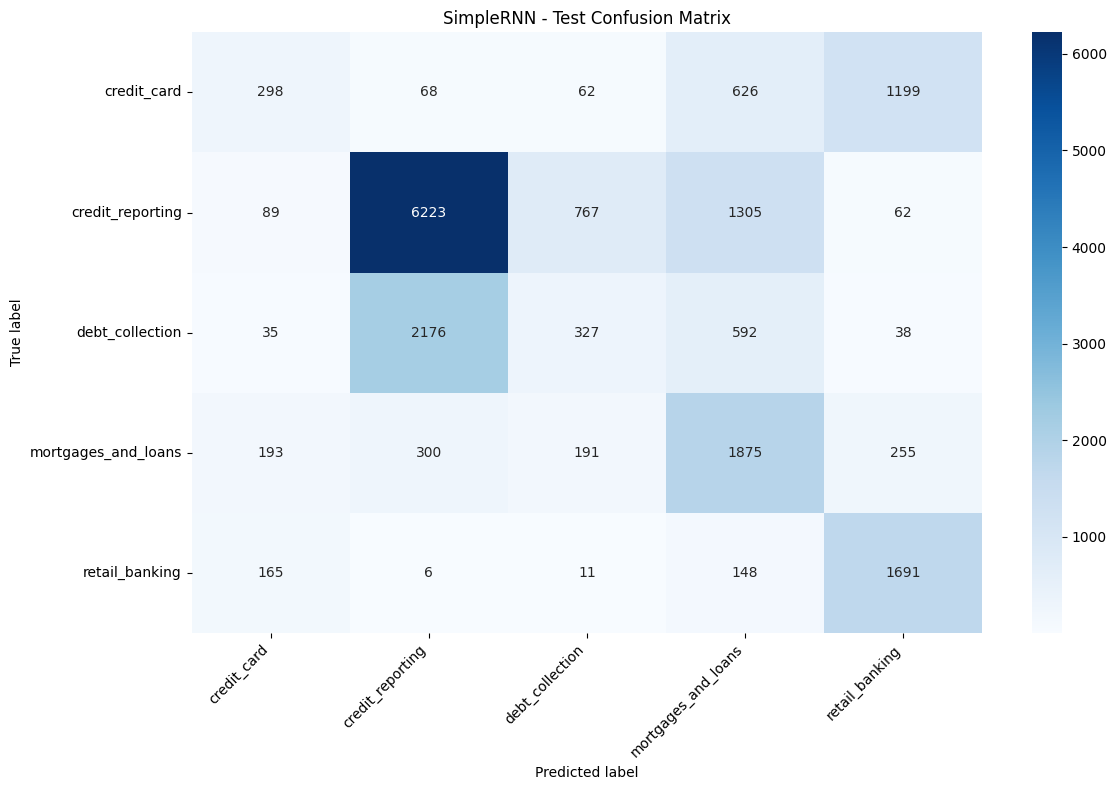

===== Bidirectional LSTM =====
Test accuracy: 0.8200
Macro F1:      0.8113
Weighted F1:   0.8222

Classification report:
                     precision    recall  f1-score   support

        credit_card       0.73      0.83      0.77      2253
   credit_reporting       0.93      0.78      0.85      8446
    debt_collection       0.73      0.82      0.77      3168
mortgages_and_loans       0.74      0.90      0.81      2814
     retail_banking       0.84      0.86      0.85      2021

           accuracy                           0.82     18702
          macro avg       0.79      0.84      0.81     18702
       weighted avg       0.83      0.82      0.82     18702



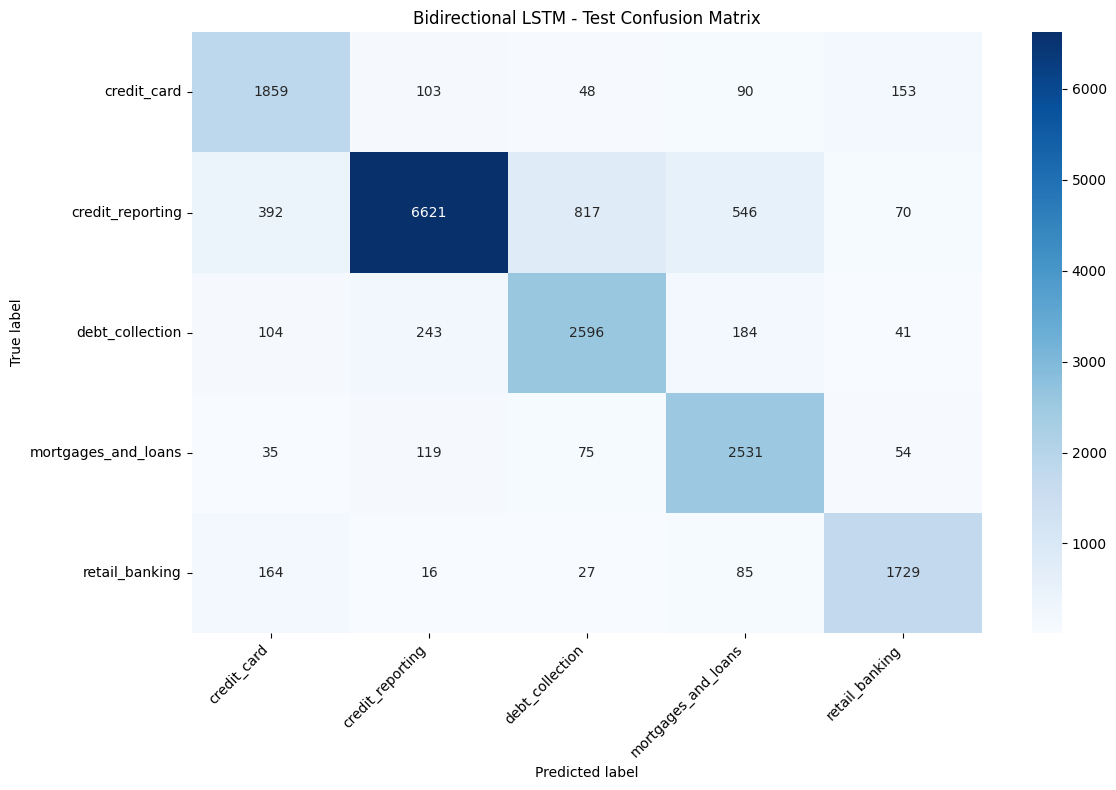

===== GRU =====
Test accuracy: 0.8290
Macro F1:      0.8184
Weighted F1:   0.8308

Classification report:
                     precision    recall  f1-score   support

        credit_card       0.74      0.82      0.78      2253
   credit_reporting       0.92      0.81      0.86      8446
    debt_collection       0.73      0.81      0.77      3168
mortgages_and_loans       0.78      0.88      0.82      2814
     retail_banking       0.83      0.88      0.85      2021

           accuracy                           0.83     18702
          macro avg       0.80      0.84      0.82     18702
       weighted avg       0.84      0.83      0.83     18702



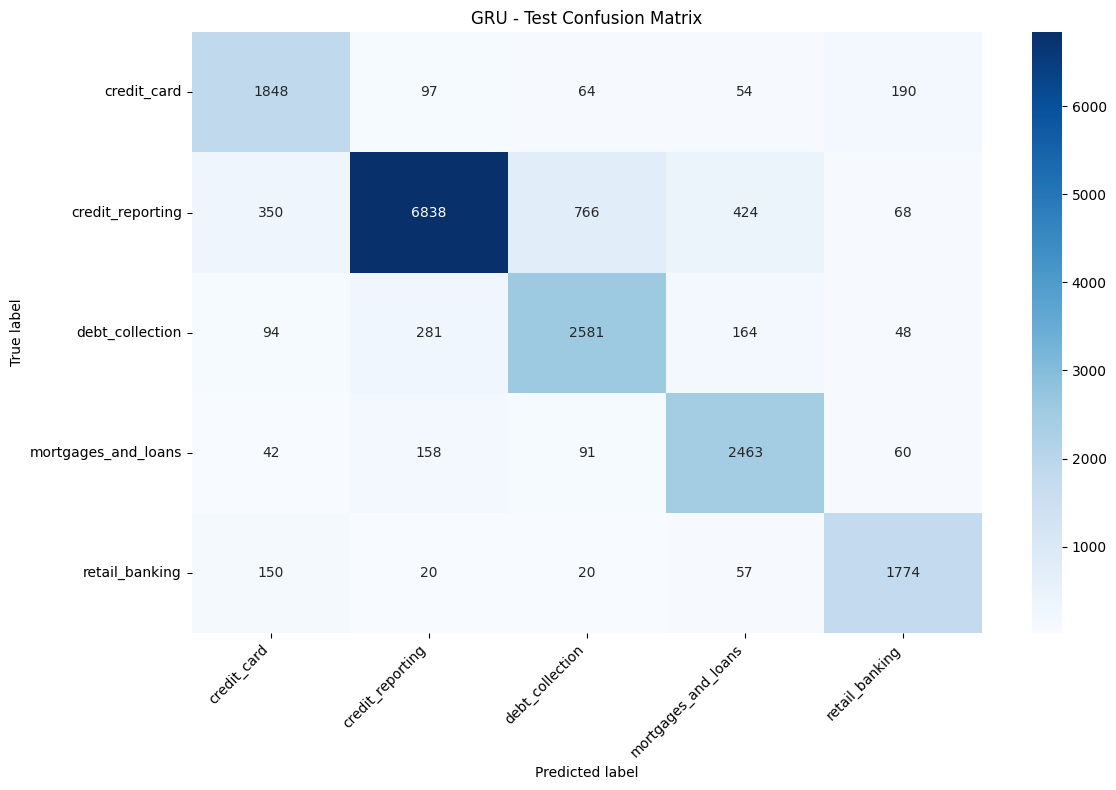

,Model,Accuracy,Macro F1,Weighted F1
2,GRU,0.829002,0.818440,0.830782
1,Bidirectional LSTM,0.820019,0.811293,0.822193
0,SimpleRNN,0.556839,0.443111,0.520641


In [32]:
def evaluate_model(model, X_eval, y_true, label_encoder, model_name):
    probabilities = model.predict(X_eval, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    labels = np.arange(len(label_encoder.classes_))

    print(f"===== {model_name} =====")
    print(f"Test accuracy: {accuracy_score(y_true, predictions):.4f}")
    print(f"Macro F1:      {f1_score(y_true, predictions, average='macro', zero_division=0):.4f}")
    print(f"Weighted F1:   {f1_score(y_true, predictions, average='weighted', zero_division=0):.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_true,
        predictions,
        labels=labels,
        target_names=label_encoder.classes_,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, predictions, labels=labels)
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        cm,
        annot=True if len(labels) <= 12 else False,
        fmt='d',
        cmap='Blues',
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.title(f'{model_name} - Test Confusion Matrix')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, predictions),
        'Macro F1': f1_score(y_true, predictions, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_true, predictions, average='weighted', zero_division=0)
    }

rnn_results = evaluate_model(
    rnn_model, X_test_pad, y_test, le, 'SimpleRNN'
)
lstm_results = evaluate_model(
    lstm_model, X_test_pad, y_test, le, 'Bidirectional LSTM'
)

gru_results = evaluate_model(
    gru_model, X_test_pad, y_test, le, 'GRU'
)

results_df = pd.DataFrame([rnn_results, lstm_results,gru_results]).sort_values(
    by='Macro F1', ascending=False
)
display(results_df)


# Training Curves
Compare training and validation loss/accuracy to check for overfitting and training stability.

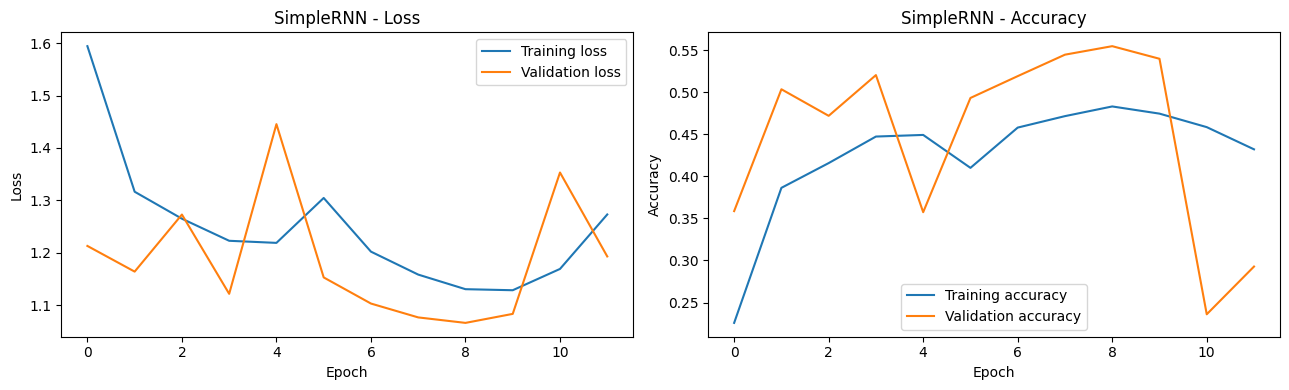

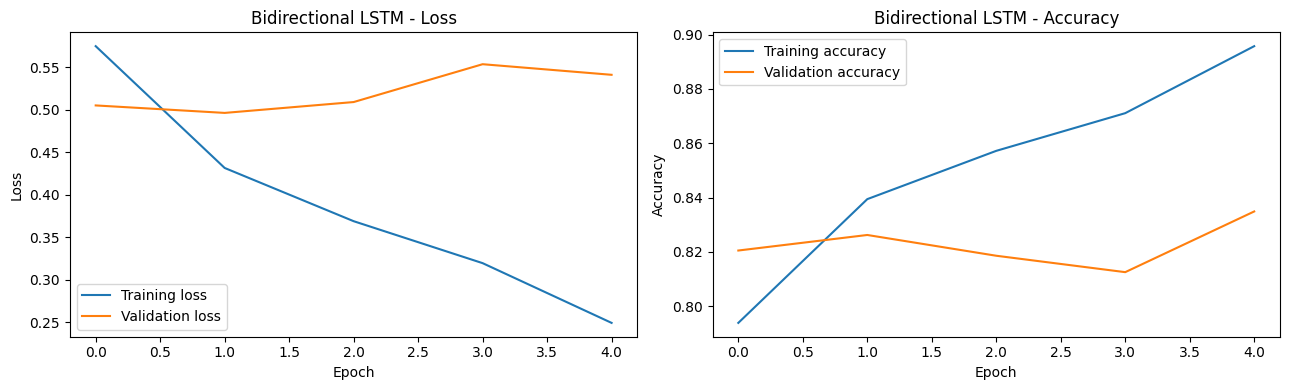

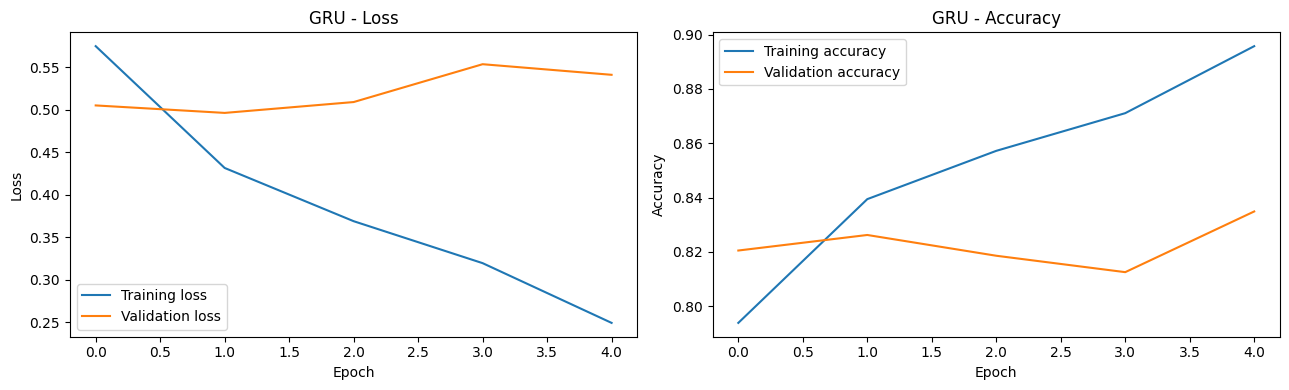

In [33]:
def plot_training_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history.history['loss'], label='Training loss')
    axes[0].plot(history.history['val_loss'], label='Validation loss')
    axes[0].set_title(f'{model_name} - Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(history.history['accuracy'], label='Training accuracy')
    axes[1].plot(history.history['val_accuracy'], label='Validation accuracy')
    axes[1].set_title(f'{model_name} - Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history_rnn, 'SimpleRNN')
plot_training_history(history_lstm, 'Bidirectional LSTM')
plot_training_history(history_lstm, 'GRU')


In [34]:
gru_model.save('customer_complaint_gru1.keras')

In [35]:
!pip install -q transformers accelerate

In [36]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [37]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer_bert = AutoTokenizer.from_pretrained(MODEL_NAME)
NUM_CLASSES = len(le.classes_)
MAX_LENGTH = 256

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [38]:
class ComplaintDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = str(self.texts[index])
        label = int(self.labels[index])

        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length
        )

        encoding["labels"] = label

        return encoding

In [39]:
train_dataset = ComplaintDataset(
    X_train_text,
    y_train,
    tokenizer_bert,
    MAX_LENGTH
)

val_dataset = ComplaintDataset(
    X_val_text,
    y_val,
    tokenizer_bert,
    MAX_LENGTH
)

test_dataset = ComplaintDataset(
    X_test_text,
    y_test,
    tokenizer_bert,
    MAX_LENGTH
)

In [40]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer_bert)

In [41]:
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME,num_labels=NUM_CLASSES)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [42]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, predictions)

    macro_f1 = f1_score(
        labels,
        predictions,
        average='macro'
    )

    weighted_f1 = f1_score(
        labels,
        predictions,
        average='weighted'
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

In [43]:
training_args = TrainingArguments(
    output_dir="./distilbert_complaints",

    num_train_epochs=3,

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    save_total_limit=1,

    logging_steps=100,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

In [44]:
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer_bert
)

In [45]:
print("Training DistilBERT...")
trainer.train()

Training DistilBERT...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.837718,0.788497,0.859259,0.844834,0.858471
2,0.684148,0.765925,0.862842,0.848446,0.862706
3,0.577113,0.767518,0.865996,0.852223,0.865788


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=8184, training_loss=0.7637727775648309, metrics={'train_runtime': 3755.4756, 'train_samples_per_second': 69.717, 'train_steps_per_second': 2.179, 'total_flos': 1.6974716553765e+16, 'train_loss': 0.7637727775648309, 'epoch': 3.0})